# 최종 정리본
# 0. 제공된 파일과 컬럼 역할 구분(현장 이해)
### 1. 운전 조건
- steel_grade : 생산하는 steel 종류(등급)
- target_thickness_mm : 목표 제품 두께(mm)
- entry_temp_c : 들어가는 온도(℃)
- line_speed_mpm : 라인 회전 속도(mpm)

### 2. 압연 설비
- rolling_force_ton : 압연 하중(ton)
- roll_gap_corr_mm : 롤 간격 보정값(mm)
- workroll_vib_mm_s : 작업롤 진동(mm/s)
- motor_current_a : 모터 전류(A)

### 3. 유압 계통
- hyd_pressure_bar : 유압 계통 압력(bar)
- hyd_oiltemp_c : 작동유 온도(℃)
- hyd_level_pct : 유압 탱크 유면(%)

### 4. 품질
- thickness_dev_mm : 목표 두께 편차(mm)

### 5. 주의
- days_to_next_roll_change : 다음 롤 교체까지 남은 일수(미래 정보 -> 라벨 누수 주의)
- post_maintenance_result : 정비 후 결과(미래 정보 -> 라벨 누수 주의)


# 1. 두 그래프 그리고 '지속변화'가 시작되는 시점 찾기
### Q1. 어느 날부터 이전과 다른 지속 변화가 보이나요?
- A1. 41일 ~ 43일 사이
- R1. 두 그래프 모두 40일 이전까지는 적은 수준으로 규칙적인 증가와 감소를 반복하지만 41일 이후 급격한 증가를 보임

### Q2. 그 변화는 스파이크인가요, 누적되는 추세인가요?
- A2. 누적되는 추세
- R2. 한 시점만 튀는 변화가 아니라 지속적으로 증가하는 추세이므로

### Q3. 두 그래프의 변화 시점은 비슷한가요?
- A3. O
- R3. 41일 이후 뚜렷하게 증가 추세 성향


# 2. 네 가지 원인 후보를 관련 신호와 이력으로 하나씩 검토
### 2-1. 작업롤 마모
- roll_gap_corr, thickness_dev, workroll_vib, 롤 교체 이력
### 2-1 사실
1. 롤 갭 보졍량과 두께 편차가 동반 증가하는 기간동안 진동 또한 완만한 증가 추세를 보임
2. 진동만으로는 마모를 확정할 수 없지만 롤 갭 보정량과 두께 편차의 보조 근거로 충분
3. 67일에 작업롤 교체 이후 롤 갭 보정량과 두께 편차가 급격히 감소함
### 2-1 결론
- 작업롤 마모는 시간에 따른 롤 마모 -> 롤 갭 보정량 증가 + 제품 품질 악화 -> 롤 교체 -> 정상화의 흐름이 확인되므로 가장 가능성이 높음

### 2-2. 유압계통 이상
- hyd_pressure_bar, hyd_oiltemp, hyd_level_pct, 유압 정비 이력
### 2-2 사실
1. 유압 압력 그래프는 150 ~ 155 bar 사이에서 증감을 반복하며 장기 추세는 보이지않음
2. 유온과 유면도 일정한 수준에서 증감을 반복하며 장기 추세는 보이지않음
3. 49일 부근에서 유압 압력 스파이크가 발생하지만 다음 날 정상 범위로 돌아오고, 같은 시점에 유온과 유면은 이상이 없으므로 센서 문제로 의심
4. 정비 이력에서 49일에 유압 압력 센서 점검으로 접촉 불량 확인해 단자 재체결 이력이 확인 가능하므로 측정 센서 문제가 타당
### 2-2 결론
- 유압 계통은 주된 원인 후보에서 우선순위가 낮다

### 2-3. 운전조건 변화
- steel_grade, entry_temp, line_speed, rolling_force, motor_current
### 2-3 사실
1. 20일 전후로 라인속도와 인입 온도는 다른 날보다 크게 하강
2. 20일 전후로 압연하중과 모터 전류는 다른 날보다 크게 상승
3. 20일 전후의 높은 압연 하중과 전류는 특정 제품(SAPH440)과 낮은 소재 온도라는 정상 운전조건 변화로 설명 가능
### 2-3 결론
- 운전조건 변화는 롤 마모의 주 원인 후보에서 우선 순위가 낮지만 정상 범위를 결정하는 주요 변수이므로 배제해서는 안 된다

### 2-4. 센서 이상
- 한 컬럼만 급변?물리적으로 가능?관련 컬럼 동시 반응?센서 점검이력
### 2-4 사실
1. 49일 유압 센서 스파이크 -> 교체 -> 정상 범위 복귀 -> 정비 이력에서 센서 교체 이력 확인
2. 물리적으로 가능
3. 유온과 유면 데이터는 큰 변화 없이 정상 범위와 비슷한 수준 유지
4. 49일 M03 센서 접촉 불량으로 인한 교체 작업 확인
### 2-4 결론
- 49일의 유압 스파이크는 센서 이상으로 판단하는 것이 적합하므로 롤 마모 주 원인에서 배제 가능

### 2-5 최종 결론
- 가장 가능성이 높은 원인 : 작업롤 마모
- 근거
    1. 41일부터 롤 갭 보정량과 두게 편차 지속 증가 추세
    2. 67일 작업롤 교체 이후 두 값이 정상 범위로 즉시 복귀
    3. 유압은 장기 악화 추세 없고 49일 스파이크는 센서 이상으로 확인
    4. 20일 전후 높은 압연 하중과 모터 전류는 제품 종류와 소재 온도 변화로 설명 가능
- 배제하기 어려운 원인 : 운전조건 변화
- 운전조건 변화는 품질 악화의 주원인으로 보이지는 않지만 변수간의 상관관계가 정상 운전 수준을 바꾸므로 분석에서 완전 배제해서는 안 됨


# 3. P-F 간격과 현장 리드타임으로 보전 전략 선택
### 1. P 후보
- 41일
- 근거 : 41일 이후 롤 갭 보정량과 롤 두께 편차 장기 증가 추세
### 2. F 후보
- 65일
- 근거 : 65일에 롤 두께 편차가 최초로 0.09mm 초과
### 3. P-F 간격
- 24일
### 4. 현장 리드타임과 비교
- 현장 리드타임 = 10일
- P-F 간격 = 24일
- PF 간격 > 리드타임 이므로 P 시점에 이상을 인지하면 충분히 대응 가능(14일 확보)
### 5. 추천 전략
- PdM
- 근거
    1. 두께 편차의 주원인인 롤 갭 보정량과 두께 편차를 센서를 통해 주기적으로 측정
    2. 고장 전 장기적인 변화 추세가 나타남
    3. PF간격이 리드타임보다 크므로 대응할 시간이 충분함

# 4. 정비 이력에서 라벨 사건을 고르고 미래 정보 누수 찾기
- 선택 기록 : **M04**
A : F-5일 ~ F
B : P ~ F-2일
C : F-30일 ~ F
- 가장 적절한 라벨창 : B
- 이유
    1. A : 고장에 너무 가까운 구간만 1로 만들어서 리드타임을 확보할 수 없음
    2. B : 변화가 시작되는 P점부터 학습하고 이미 고장이 진행된 F 최근접 구간은 제외해서 예측에 가장 적합
    3. C : P보다 앞선 정상 구간까지 1로 포함해서 라벨 신뢰도가 떨어질 수 있음
- 라벨 누수 후보
    - days_to_next_roll_change : 실제 미래의 롤 교체일을 알아야 알 수 있는 정보 -> 경보 당시에는 알 수 없는 정보
    - post_maintenance_result : 정비 이후 기록되는 정보 -> 경보 당시에는 알 수 없는 정보
    - 공통점 : 예측 당시에는 알 수 없는 **미래** 정보

# 5. 최종 결론
### 분석안 항목
1. 가장 가능성이 높은 원인과 근거 2개
- 가장 가능성이 높은 원인 : 작업롤 마모
- 근거1 : 41일부터 롤 갭 보정량과 두께 편차가 장기간 함께 증가 추세
- 근거2 : 67일 작업 롤 교체 이후 두 값 모두 정상 범위로 즉시 복귀

2. 배제한 원인과 배제한 근거
- 배제한 원인1 : 유압계통 이상
    - 근거1 : 압력, 유온, 유면의 장기적인 동반 악화 추세 없음
    - 근거2 : 49일 압력 스파이크는 센서 문제인 것을 확인

- 배제한 원인2 : 센서 이상
    - 근거 : 49일 압력 스파이크에는 센서 이상이 존재하지만 작업 롤의 장기적 추세는 설명 못 함

- 배제한 원인3 : 운전조건 변화
    - 근거 : 18~22일 사이 특정 제품과 낮은 인입 온도로 압연 하중과 전류는 상승하지만 동일 기간 롤 갭 보정량과 두께 편차는 정상


3. P후보, F후보, P-F 간격
- P후보 : 41일
- F후보 : 65일
- P-F 간격 : 24일


4. 추천 보전 전략과 기존 임계치의 역할
- 추천 전략 : PdM
- 기존 임계치의 역할 : 최종 품질 보호 기준(F점)으로 유지


5. 라벨 사건, 라벨 1구간, 제외 구간
- 라벨 사건 : M04 작업롤 마모 확인 후 교체
- 라벨 1 : 41~63일(P ~ F-2일)
- 제외 구간 : 64 ~ 67일(고장이 이미 최종 진행됐다고 판단)
- 교체 후 : 교체 후 안정 여부를 확인하기 위해 68일 이후는 정상 후보로 재검토

6. 라벨 누수 컬럼
- days_to_next_roll_change
- post_maintenance_result


7. 현재 데이터의 한계와 추가 요청 데이터
- 현재 데이터의 한계
    1. 사례 수 : 정비 로그에 작업롤 마모 사건이 단 한 건뿐으로 일반화하기에는 너무 적은 사례 수
    2. 샘플링 주기 : 하루 단위 측정 데이터이므로 분당, 초당 미세 변화가 사라진 데이터
    3. 진동 정보 : 진동 컬럼은 요약값이므로 구체적인 원인 진단은 어려움
    4. 운전 조건 범위 : 실제 압연 공정을 설명할 수 있는 모든 조건이 반영되진 않음
    5. 정비 사건 시각 : 현재는 일 단위 기록이므로 실제 열화 시작, 교체 시점의 정확한 연결에는 한계가 있음
- 추가 요청 데이터
    1. 더 많고 장기간 축적한 작업롤 마모 사건 정비 로그
    2. 데이터들의 측정 주기를 일 단위에서 더 짧은 주기로 변경
    3. 정확한 진동 정보를 위한 원시 파형, 방향 데이터, 가속도 데이터
    4. 더 다양한 압연 운전 관련 데이터(출측온도)

### 최종의견
- 이 라인에서는 작업롤 마모가 가장 유력함. 약 41일부터 롤 갭 보정량과 두께 편차가 장기간 함께 증가했고, 67일 작업롤 교체 이후 동시에 정상범위로 복귀한 것이 핵심 근거. PF 간격은 24일로 리드타임 10일보다 14일 여유있으므로 PdM 적용이 적합. 


5일차 실습에 있는

최종종합실습_열연압연_예지보전.pptx 및 관련 자료 참고하여

조별 발표 준비 부탁드립니다.

실습  | 열연 압연 종합 과제

데이터: 열연압연_운전데이터.csv, 열연압연_정비이력.csv

시작 코드: 열연압연_시작코드.py

답안: 열연압연_강사용_핵심정답.txt, 최종종합실습_열연압연_전체_모범답안.txt

1. 롤 갭 보정량과 두께 편차를 시간축으로 확인한다.

2. 열화(P)와 기능 고장(F), 롤 교체 시점을 데이터와 정비이력으로 연결한다.

3. 교체 후 결과와 다음 교체까지 남은 일수 등 미래 정보 누수를 찾는다.

4. 현장 적용에 필요한 입력만 남기고 경보 목적, 대응시간, 성과 지표를 제안한다.

5. 고장 시점과 P/F 시점은 관측값에 근거해 구간으로 보고하고 단일 날짜의 확정 오차를 논의한다.

제출: 전략 선택표, 성과 계산, 라벨 정의, 누수 컬럼 목록, 적용 한계 및 대응안

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
operation_data = pd.read_csv("열연압연_운전데이터.csv")
maint_log = pd.read_csv("열연압연_정비이력.csv")

### 0. 제공된 파일과 컬럼 역할 구분(현장 이해)

In [3]:
operation_data.shape

(80, 16)

In [4]:
maint_log.shape

(5, 7)

In [5]:
operation_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   day                       80 non-null     int64  
 1   date                      80 non-null     str    
 2   steel_grade               80 non-null     str    
 3   target_thickness_mm       80 non-null     float64
 4   entry_temp_c              80 non-null     float64
 5   line_speed_mpm            80 non-null     float64
 6   rolling_force_ton         80 non-null     float64
 7   roll_gap_corr_mm          80 non-null     float64
 8   thickness_dev_mm          80 non-null     float64
 9   workroll_vib_mm_s         80 non-null     float64
 10  motor_current_a           80 non-null     float64
 11  hyd_pressure_bar          80 non-null     float64
 12  hyd_oiltemp_c             80 non-null     float64
 13  hyd_level_pct             80 non-null     float64
 14  days_to_next_roll_chang

In [6]:
maint_log.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   record_id    5 non-null      str  
 1   event_date   5 non-null      str  
 2   day          5 non-null      int64
 3   equipment    5 non-null      str  
 4   work_type    5 non-null      str  
 5   description  5 non-null      str  
 6   result       5 non-null      str  
dtypes: int64(1), str(6)
memory usage: 867.0 bytes


In [7]:
maint_log.columns

Index(['record_id', 'event_date', 'day', 'equipment', 'work_type',
       'description', 'result'],
      dtype='str')

In [8]:
operation_data.columns

Index(['day', 'date', 'steel_grade', 'target_thickness_mm', 'entry_temp_c',
       'line_speed_mpm', 'rolling_force_ton', 'roll_gap_corr_mm',
       'thickness_dev_mm', 'workroll_vib_mm_s', 'motor_current_a',
       'hyd_pressure_bar', 'hyd_oiltemp_c', 'hyd_level_pct',
       'days_to_next_roll_change', 'post_maintenance_result'],
      dtype='str')

In [9]:
operation_data.head(3)

,day,date,steel_grade,target_thickness_mm,entry_temp_c,line_speed_mpm,rolling_force_ton,roll_gap_corr_mm,thickness_dev_mm,workroll_vib_mm_s,motor_current_a,hyd_pressure_bar,hyd_oiltemp_c,hyd_level_pct,days_to_next_roll_change,post_maintenance_result
0,1,2026-06-01,SS400,3.2,1188.2,763.0,1654.2,0.088,0.026,2.23,213.6,152.2,44.3,88.6,66.0,롤 표면 마모 확인
1,2,2026-06-02,SS400,3.2,1180.4,749.6,1663.7,0.091,0.030,2.30,214.6,150.8,44.1,88.6,65.0,롤 표면 마모 확인
2,3,2026-06-03,SPHC,2.0,1182.5,847.5,1546.4,0.126,0.023,2.23,206.9,153.1,44.0,88.8,64.0,롤 표면 마모 확인


In [10]:
maint_log.head(3)

,record_id,event_date,day,equipment,work_type,description,result
0,M01,2026-06-14,14,작업롤,점검,표면 및 진동 점검,이상 없음
1,M02,2026-07-01,31,유압 유닛,예방정비,필터 정기 교체,정상
2,M03,2026-07-19,49,유압 압력 센서,점검,압력값 단발성 급등 확인 후 단자 재체결,센서 접촉 불량 확인


### 1. 운전 조건
- steel_grade : 생산하는 steel 종류(등급)
- target_thickness_mm : 목표 제품 두께(mm)
- entry_temp_c : 들어가는 온도(℃)
- line_speed_mpm : 라인 회전 속도(mpm)

### 2. 압연 설비
- rolling_force_ton : 압연 하중(ton)
- roll_gap_corr_mm : 롤 간격 보정값(mm)
- workroll_vib_mm_s : 작업롤 진동(mm/s)
- motor_current_a : 모터 전류(A)

### 3. 유압 계통
- hyd_pressure_bar : 유압 계통 압력(bar)
- hyd_oiltemp_c : 작동유 온도(℃)
- hyd_level_pct : 유압 탱크 유면(%)

### 4. 품질
- thickness_dev_mm : 목표 두께 편차(mm)

### 5. 주의
- days_to_next_roll_change : 다음 롤 교체까지 남은 일수(미래 정보 -> 라벨 누수 주의)
- post_maintenance_result : 정비 후 결과(미래 정보 -> 라벨 누수 주의)

# 1. 두 그래프 그리고 '지속변화'가 시작되는 시점 찾기

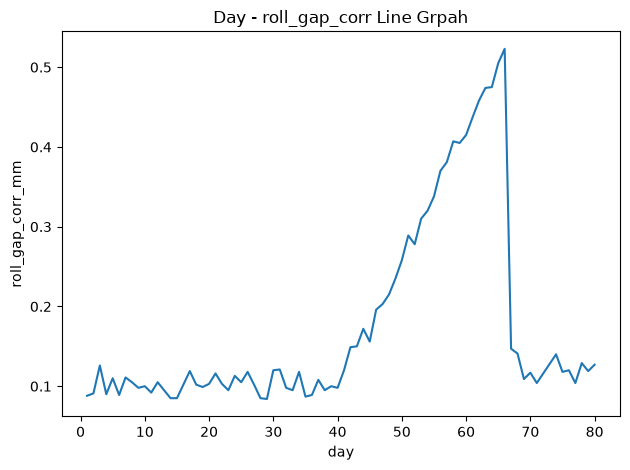

In [13]:
sns.lineplot(operation_data, x='day', y='roll_gap_corr_mm')
plt.title('Day - roll_gap_corr Line Grpah')
plt.tight_layout()
plt.show()

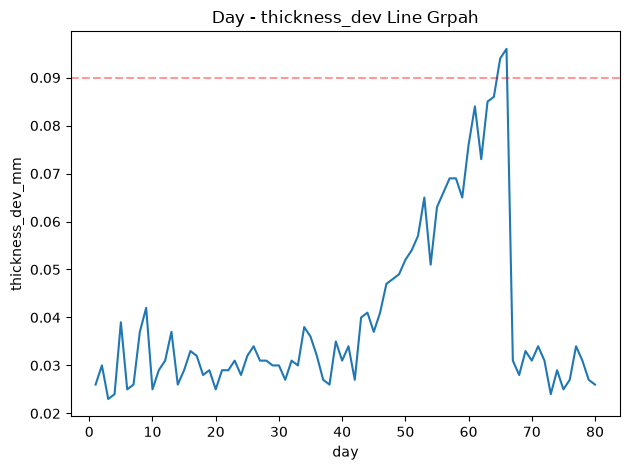

In [15]:
sns.lineplot(operation_data, x='day', y='thickness_dev_mm')
plt.title('Day - thickness_dev Line Grpah')
plt.axhline(0.09, linestyle='--', color='red', alpha=0.4)
plt.tight_layout()
plt.show()

### Q1. 어느 날부터 이전과 다른 지속 변화가 보이나요?
- A1. 41일 ~ 43일 사이
- R1. 두 그래프 모두 40일 이전까지는 적은 수준으로 규칙적인 증가와 감소를 반복하지만 41일 이후 급격한 증가를 보임

### Q2. 그 변화는 스파이크인가요, 누적되는 추세인가요?
- A2. 누적되는 추세
- R2. 한 시점만 튀는 변화가 아니라 지속적으로 증가하는 추세이므로

### Q3. 두 그래프의 변화 시점은 비슷한가요?
- A3. O
- R3. 41일 이후 뚜렷하게 증가 추세 성향

# 2. 네 가지 원인 후보를 관련 신호와 이력으로 하나씩 검토

### 2-1. 작업롤 마모
- roll_gap_corr, thickness_dev, workroll_vib, 롤 교체 이력

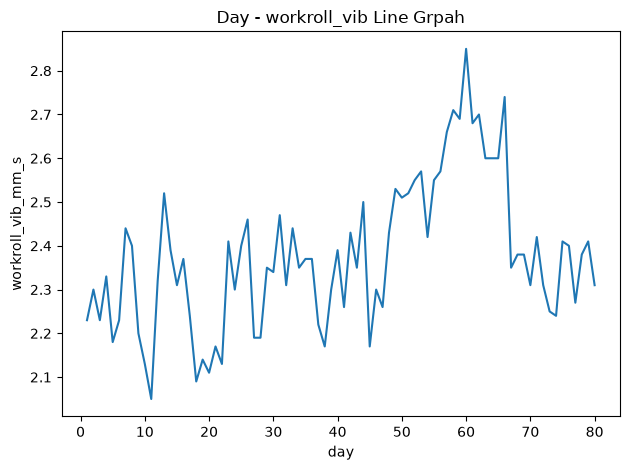

In [20]:
sns.lineplot(operation_data, x='day', y='workroll_vib_mm_s')
plt.title('Day - workroll_vib Line Grpah')
plt.tight_layout()
plt.show()

In [21]:
maint_log

,record_id,event_date,day,equipment,work_type,description,result
0,M01,2026-06-14,14,작업롤,점검,표면 및 진동 점검,이상 없음
1,M02,2026-07-01,31,유압 유닛,예방정비,필터 정기 교체,정상
2,M03,2026-07-19,49,유압 압력 센서,점검,압력값 단발성 급등 확인 후 단자 재체결,센서 접촉 불량 확인
3,M04,2026-08-06,67,작업롤,고장수리,두께 편차 증가 및 롤 표면 마모 확인 후 교체,교체 후 두께 편차 정상화
4,M05,2026-08-13,74,작업롤,예방정비,정기 윤활 및 표면 점검,이상 없음


### 2-1 사실
1. 롤 갭 보졍량과 두께 편차가 동반 증가하는 기간동안 진동 또한 완만한 증가 추세를 보임
2. 진동만으로는 마모를 확정할 수 없지만 롤 갭 보정량과 두께 편차의 보조 근거로 충분
3. 67일에 작업롤 교체 이후 롤 갭 보정량과 두께 편차가 급격히 감소함

### 2-1 결론
- 작업롤 마모는 시간에 따른 롤 마모 -> 롤 갭 보정량 증가 + 제품 품질 악화 -> 롤 교체 -> 정상화의 흐름이 확인되므로 가장 가능성이 높음

In [16]:
operation_data.columns

Index(['day', 'date', 'steel_grade', 'target_thickness_mm', 'entry_temp_c',
       'line_speed_mpm', 'rolling_force_ton', 'roll_gap_corr_mm',
       'thickness_dev_mm', 'workroll_vib_mm_s', 'motor_current_a',
       'hyd_pressure_bar', 'hyd_oiltemp_c', 'hyd_level_pct',
       'days_to_next_roll_change', 'post_maintenance_result'],
      dtype='str')

In [17]:
maint_log.columns

Index(['record_id', 'event_date', 'day', 'equipment', 'work_type',
       'description', 'result'],
      dtype='str')

In [18]:
maint_log.head(1)

,record_id,event_date,day,equipment,work_type,description,result
0,M01,2026-06-14,14,작업롤,점검,표면 및 진동 점검,이상 없음


### 2-2. 유압계통 이상
- hyd_pressure_bar, hyd_oiltemp, hyd_level_pct, 유압 정비 이력

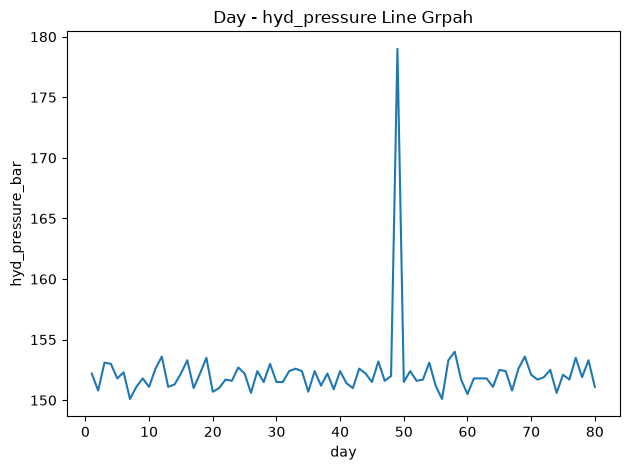

In [3]:
sns.lineplot(operation_data, x='day', y='hyd_pressure_bar')
plt.title('Day - hyd_pressure Line Grpah')
plt.tight_layout()
plt.show()

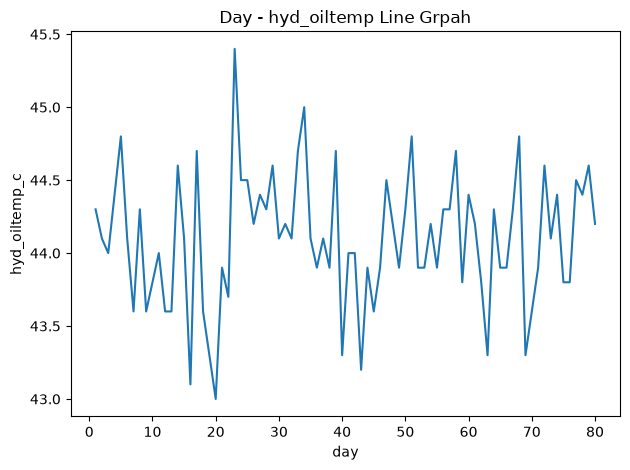

In [4]:
sns.lineplot(operation_data, x='day', y='hyd_oiltemp_c')
plt.title('Day - hyd_oiltemp Line Grpah')
plt.tight_layout()
plt.show()

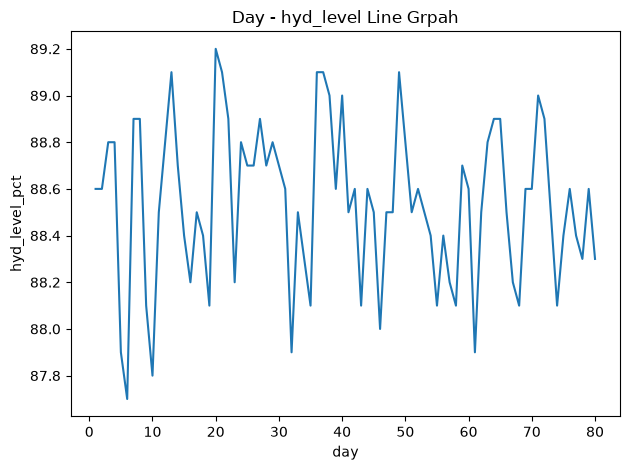

In [5]:
sns.lineplot(operation_data, x='day', y='hyd_level_pct')
plt.title('Day - hyd_level Line Grpah')
plt.tight_layout()
plt.show()

In [6]:
maint_log

,record_id,event_date,day,equipment,work_type,description,result
0,M01,2026-06-14,14,작업롤,점검,표면 및 진동 점검,이상 없음
1,M02,2026-07-01,31,유압 유닛,예방정비,필터 정기 교체,정상
2,M03,2026-07-19,49,유압 압력 센서,점검,압력값 단발성 급등 확인 후 단자 재체결,센서 접촉 불량 확인
3,M04,2026-08-06,67,작업롤,고장수리,두께 편차 증가 및 롤 표면 마모 확인 후 교체,교체 후 두께 편차 정상화
4,M05,2026-08-13,74,작업롤,예방정비,정기 윤활 및 표면 점검,이상 없음


### 2-2 사실
1. 유압 압력 그래프는 150 ~ 155 bar 사이에서 증감을 반복하며 장기 추세는 보이지않음
2. 유온과 유면도 일정한 수준에서 증감을 반복하며 장기 추세는 보이지않음
3. 49일 부근에서 유압 압력 스파이크가 발생하지만 다음 날 정상 범위로 돌아오고, 같은 시점에 유온과 유면은 이상이 없으므로 센서 문제로 의심
4. 정비 이력에서 49일에 유압 압력 센서 점검으로 접촉 불량 확인해 단자 재체결 이력이 확인 가능하므로 측정 센서 문제가 타당


### 2-2 결론
- 유압 계통은 주된 원인 후보에서 우선순위가 낮다

### 2-3. 운전조건 변화
- steel_grade, entry_temp, line_speed, rolling_force, motor_current

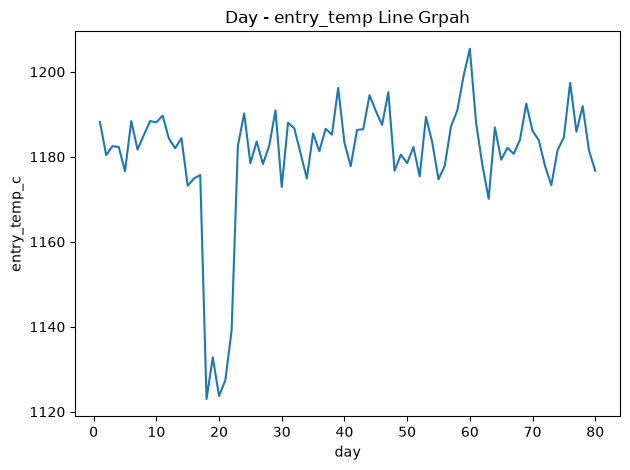

In [7]:
sns.lineplot(operation_data, x='day', y='entry_temp_c')
plt.title('Day - entry_temp Line Grpah')
plt.tight_layout()
plt.show()

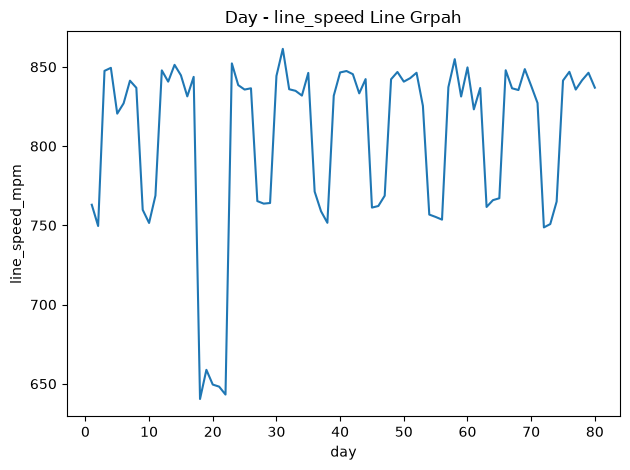

In [11]:
sns.lineplot(operation_data, x='day', y='line_speed_mpm')
plt.title('Day - line_speed Line Grpah')
plt.tight_layout()
plt.show()

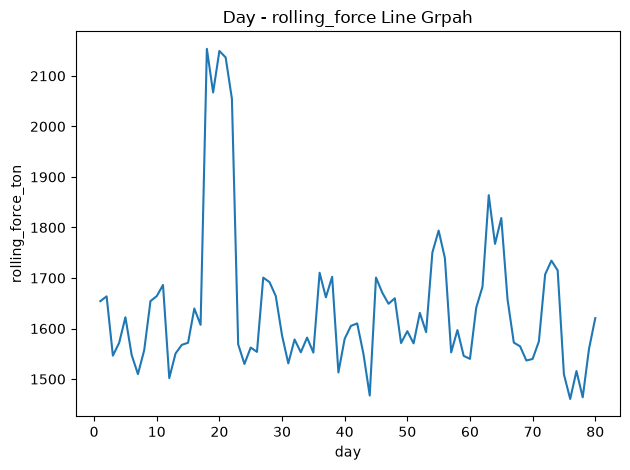

In [ ]:
sns.lineplot(operation_data, x='day', y='rolling_force_ton')
plt.title('Day - rolling_force Line Grpah')
plt.tight_layout()
plt.show()

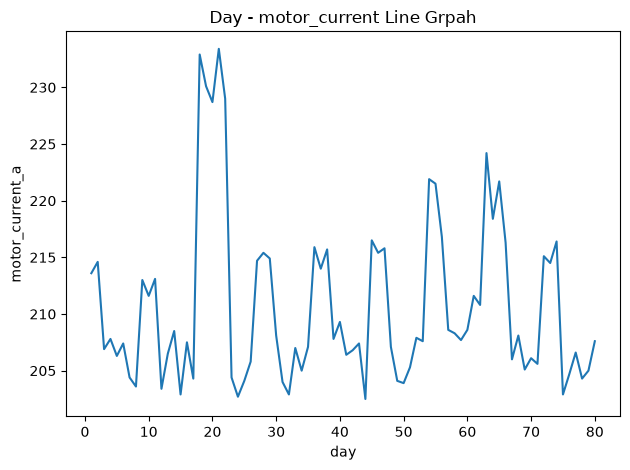

In [14]:
sns.lineplot(operation_data, x='day', y='motor_current_a')
plt.title('Day - motor_current Line Grpah')
plt.tight_layout()
plt.show()

In [16]:
operation_data.iloc[16:24]

,day,date,steel_grade,target_thickness_mm,entry_temp_c,line_speed_mpm,rolling_force_ton,roll_gap_corr_mm,thickness_dev_mm,workroll_vib_mm_s,motor_current_a,hyd_pressure_bar,hyd_oiltemp_c,hyd_level_pct,days_to_next_roll_change,post_maintenance_result
16,17,2026-06-17,SPHC,2.0,1175.7,843.7,1607.4,0.119,0.032,2.24,204.3,151.0,44.7,88.5,50.0,롤 표면 마모 확인
17,18,2026-06-18,SAPH440,4.5,1123.0,640.4,2153.5,0.102,0.028,2.09,232.9,152.2,43.6,88.4,49.0,롤 표면 마모 확인
18,19,2026-06-19,SAPH440,4.5,1132.8,658.8,2067.2,0.099,0.029,2.14,230.1,153.5,43.3,88.1,48.0,롤 표면 마모 확인
19,20,2026-06-20,SAPH440,4.5,1123.7,649.5,2149.3,0.103,0.025,2.11,228.7,150.7,43.0,89.2,47.0,롤 표면 마모 확인
20,21,2026-06-21,SAPH440,4.5,1127.4,648.2,2136.5,0.116,0.029,2.17,233.4,151.0,43.9,89.1,46.0,롤 표면 마모 확인
21,22,2026-06-22,SAPH440,4.5,1139.1,643.2,2054.5,0.103,0.029,2.13,229.0,151.7,43.7,88.9,45.0,롤 표면 마모 확인
22,23,2026-06-23,SPHC,2.0,1182.5,852.2,1568.8,0.095,0.031,2.41,204.4,151.6,45.4,88.2,44.0,롤 표면 마모 확인
23,24,2026-06-24,SPHC,2.0,1190.2,838.5,1529.9,0.113,0.028,2.30,202.7,152.7,44.5,88.8,43.0,롤 표면 마모 확인


### 2-3 사실
1. 20일 전후로 라인속도와 인입 온도는 다른 날보다 크게 하강
2. 20일 전후로 압연하중과 모터 전류는 다른 날보다 크게 상승
3. 20일 전후의 높은 압연 하중과 전류는 특정 제품(SAPH440)과 낮은 소재 온도라는 정상 운전조건 변화로 설명 가능

### 2-3 결론
- 운전조건 변화는 롤 마모의 주 원인 후보에서 우선 순위가 낮지만 정상 범위를 결정하는 주요 변수이므로 배제해서는 안 된다

### 2-4. 센서 이상
- 한 컬럼만 급변?물리적으로 가능?관련 컬럼 동시 반응?센서 점검이력

### 2-4 사실
1. 49일 유압 센서 스파이크 -> 교체 -> 정상 범위 복귀 -> 정비 이력에서 센서 교체 이력 확인
2. 물리적으로 가능
3. 유온과 유면 데이터는 큰 변화 없이 정상 범위와 비슷한 수준 유지
4. 49일 M03 센서 접촉 불량으로 인한 교체 작업 확인

### 2-4 결론
- 49일의 유압 스파이크는 센서 이상으로 판단하는 것이 적합하므로 롤 마모 주 원인에서 배제 가능

### 2-5 최종 결론
- 가장 가능성이 높은 원인 : 작업롤 마모
- 근거
    1. 41일부터 롤 갭 보정량과 두게 편차 지속 증가 추세
    2. 67일 작업롤 교체 이후 두 값이 정상 범위로 즉시 복귀
    3. 유압은 장기 악화 추세 없고 49일 스파이크는 센서 이상으로 확인
    4. 20일 전후 높은 압연 하중과 모터 전류는 제품 종류와 소재 온도 변화로 설명 가능
- 배제하기 어려운 원인 : 운전조건 변화
- 운전조건 변화는 품질 악화의 주원인으로 보이지는 않지만 변수간의 상관관계가 정상 운전 수준을 바꾸므로 분석에서 완전 배제해서는 안 됨

# 3. P-F 간격과 현장 리드타임으로 보전 전략 선택

### 1. P 후보
- 41일
- 근거 : 41일 이후 롤 갭 보정량과 롤 두께 편차 장기 증가 추세

### 2. F 후보
- 65일
- 근거 : 65일에 롤 두께 편차가 최초로 0.09mm 초과

### 3. P-F 간격
- 24일

### 4. 현장 리드타임과 비교
- 현장 리드타임 = 10일
- P-F 간격 = 24일
- PF 간격 > 리드타임 이므로 P 시점에 이상을 인지하면 충분히 대응 가능(14일 확보)

### 5. 추천 전략
- PdM
- 근거
    1. 두께 편차의 주원인인 롤 갭 보정량과 두께 편차를 센서를 통해 주기적으로 측정
    2. 고장 전 장기적인 변화 추세가 나타남
    3. PF간격이 리드타임보다 크므로 대응할 시간이 충분함

In [17]:
operation_data[operation_data['thickness_dev_mm'] >= 0.09]

,day,date,steel_grade,target_thickness_mm,entry_temp_c,line_speed_mpm,rolling_force_ton,roll_gap_corr_mm,thickness_dev_mm,workroll_vib_mm_s,motor_current_a,hyd_pressure_bar,hyd_oiltemp_c,hyd_level_pct,days_to_next_roll_change,post_maintenance_result
64,65,2026-08-04,SS400,3.2,1179.3,767.1,1818.6,0.505,0.094,2.60,221.7,152.5,43.9,88.9,2.0,롤 표면 마모 확인
65,66,2026-08-05,SPHC,2.0,1182.1,847.9,1657.5,0.523,0.096,2.74,216.3,152.4,43.9,88.5,1.0,롤 표면 마모 확인


# 4. 정비 이력에서 라벨 사건을 고르고 미래 정보 누수 찾기

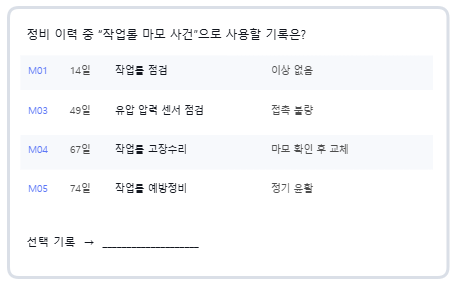

- 선택 기록 : **M04**

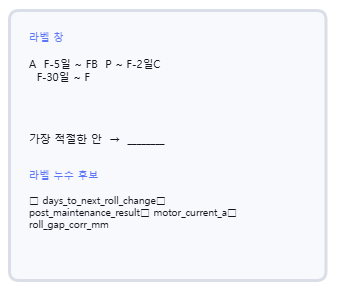

A : F-5일 ~ F
B : P ~ F-2일
C : F-30일 ~ F
- 가장 적절한 라벨창 : B
- 이유
    1. A : 고장에 너무 가까운 구간만 1로 만들어서 리드타임을 확보할 수 없음
    2. B : 변화가 시작되는 P점부터 학습하고 이미 고장이 진행된 F 최근접 구간은 제외해서 예측에 가장 적합
    3. C : P보다 앞선 정상 구간까지 1로 포함해서 라벨 신뢰도가 떨어질 수 있음

- 라벨 누수 후보
    - days_to_next_roll_change : 실제 미래의 롤 교체일을 알아야 알 수 있는 정보 -> 경보 당시에는 알 수 없는 정보
    - post_maintenance_result : 정비 이후 기록되는 정보 -> 경보 당시에는 알 수 없는 정보
    - 공통점 : 예측 당시에는 알 수 없는 **미래** 정보

# 5. 최종 결론
### 분석안 항목
1. 가장 가능성이 높은 원인과 근거 2개
- 가장 가능성이 높은 원인 : 작업롤 마모
- 근거1 : 41일부터 롤 갭 보정량과 두께 편차가 장기간 함께 증가 추세
- 근거2 : 67일 작업 롤 교체 이후 두 값 모두 정상 범위로 즉시 복귀

2. 배제한 원인과 배제한 근거
- 배제한 원인1 : 유압계통 이상
    - 근거1 : 압력, 유온, 유면의 장기적인 동반 악화 추세 없음
    - 근거2 : 49일 압력 스파이크는 센서 문제인 것을 확인

- 배제한 원인2 : 센서 이상
    - 근거 : 49일 압력 스파이크에는 센서 이상이 존재하지만 작업 롤의 장기적 추세는 설명 못 함

- 배제한 원인3 : 운전조건 변화
    - 근거 : 18~22일 사이 특정 제품과 낮은 인입 온도로 압연 하중과 전류는 상승하지만 동일 기간 롤 갭 보정량과 두께 편차는 정상


3. P후보, F후보, P-F 간격
- P후보 : 41일
- F후보 : 65일
- P-F 간격 : 24일


4. 추천 보전 전략과 기존 임계치의 역할
- 추천 전략 : PdM
- 기존 임계치의 역할 : 최종 품질 보호 기준(F점)으로 유지


5. 라벨 사건, 라벨 1구간, 제외 구간
- 라벨 사건 : M04 작업롤 마모 확인 후 교체
- 라벨 1 : 41~63일(P ~ F-2일)
- 제외 구간 : 64 ~ 67일(고장이 이미 최종 진행됐다고 판단)
- 교체 후 : 교체 후 안정 여부를 확인하기 위해 68일 이후는 정상 후보로 재검토

6. 라벨 누수 컬럼
- days_to_next_roll_change
- post_maintenance_result


7. 현재 데이터의 한계와 추가 요청 데이터
- 현재 데이터의 한계
    1. 사례 수 : 정비 로그에 작업롤 마모 사건이 단 한 건뿐으로 일반화하기에는 너무 적은 사례 수
    2. 샘플링 주기 : 하루 단위 측정 데이터이므로 분당, 초당 미세 변화가 사라진 데이터
    3. 진동 정보 : 진동 컬럼은 요약값이므로 구체적인 원인 진단은 어려움
    4. 운전 조건 범위 : 실제 압연 공정을 설명할 수 있는 모든 조건이 반영되진 않음
    5. 정비 사건 시각 : 현재는 일 단위 기록이므로 실제 열화 시작, 교체 시점의 정확한 연결에는 한계가 있음
- 추가 요청 데이터
    1. 더 많고 장기간 축적한 작업롤 마모 사건 정비 로그
    2. 데이터들의 측정 주기를 일 단위에서 더 짧은 주기로 변경
    3. 정확한 진동 정보를 위한 원시 파형, 방향 데이터, 가속도 데이터
    4. 더 다양한 압연 운전 관련 데이터(출측온도)

### 최종의견
- 이 라인에서는 작업롤 마모가 가장 유력함. 약 41일부터 롤 갭 보정량과 두께 편차가 장기간 함께 증가했고, 67일 작업롤 교체 이후 동시에 정상범위로 복귀한 것이 핵심 근거. PF 간격은 24일로 리드타임 10일보다 14일 여유있으므로 PdM 적용이 적합. 